# Modelado Predictivo: Clasificación con K-Nearest Neighbors
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI).

**Contexto:** Tomando como base el dataset limpio, libre de fugas de datos ("X_features.csv" y "y_target.csv"), este notebook implementa y evalúa el modelo **K-Nearest Neighbors** construido desde cero. KNN es un algoritmo de *aprendizaje perezoso (lazy learning)* que no construye una ecuación interna, sino que memoriza el dataset de entrenamiento y clasifica a los nuevos datos basándose en la etiqueta mayoritaria de sus K vecinos más cercanos utilizando la distancia Euclidiana.

### Objetivos del Modelado

1. **Construcción y Búsqueda Vecinal:** Instanciar el clasificador KNNClassifier programado a mano con ayuda del curso 'Machine_Learning_desde_Cero-11', que calculará la distancia geométrica exacta entre un nuevo registro cardiotocográfico y los  pacientes del conjunto de entrenamiento.

2. **Evaluación de Probabilidades:** Utilizar la proporción de votos de los vecinos más cercanos para generar una distribución de probabilidad continua 'predict_proba', indispensable para el cálculo del AUC.

3. **Análisis Clínico y Costo Computacional:** Comparar las métricas de rendimiento (F1-Score, Recall, Matriz de Confusión y ROC-AUC) frente a scikit-learn, analizando la viabilidad del modelo casero en la fase de predicción debido al alto costo computacional del cálculo de distancias por fuerza bruta.


### Ficha Metodológica del Modelo

* **Descripción breve del método:** Algoritmo no paramétrico que clasifica un paciente buscando a sus K vecinos más parecidos (menor distancia Euclidiana) en el conjunto de entrenamiento. El diagnóstico final se toma por votación mayoritaria.

* **Justificación de su uso:** Es el método más intuitivo en medicina basada en evidencia: *"Si el monitor de este paciente se comporta matemáticamente igual al de otros 5 pacientes pasados que tuvieron hipoxia, lo más probable es que este paciente también la tenga"*. Dado que depende de distancias, **la estandarización previa de los datos (Z-Score) es un paso obligatorio** para evitar que variables grandes (como los latidos base LB) dominen.

* **Métricas de evaluación utilizadas:** Exactitud Global (*Accuracy*), Matriz de Confusión, *Recall*, *Precisión*, *F1-Score* por clase, *Promedio Macro F1-Score* y el cálculo del *Área Bajo la Curva ROC (AUC)*.

* **Análisis de resultados:** Detallado al final del notebook, resaltando la sensibilidad obtenida en la clase patológica.

In [1]:
# Importación de librerías 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# Modificación para importar los modelos fuera de la carpeta actual
import os
import sys

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importación del modelo y métricas caseras
from src.Knn import KNNClassifier
from src.utils_and_metrics import train_test_split, standardize, accuracy, confusion_matrix, recall, f1_score, precision, roc

#### **Preparación de Datos: Partición y Estandarización Z-Score**
Para que la distancia Euclidiana funcione correctamente y no le dé un peso desproporcionado a variables con números grandes, debemos escalar las 21 características usando el método standardize. Para evitar fugas de información clínica, la media y desviación estándar se aprenden **solo** del conjunto de entrenamiento.

In [2]:
# Carga directa de matrices generadas en 02_EDA_Visualizacion
X_df = pd.read_csv('../data/processed/X_features.csv')
y_df = pd.read_csv('../data/processed/y_target.csv')

X = X_df.to_numpy()
y = y_df['NSP'].to_numpy().ravel().astype(int)

# Partición de datos (80% entrenamiento, 20% prueba) con seed=42 para comparación directa
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, seed=42)

# Estandarización Z-Score (calculando media y desviación estándar solo en X_train)
X_train, mean, std = standardize(X_train)
X_test = (X_test - mean) / std

# Visualización

print(f"Dimensión de Matriz X (Características): {X.shape}")
print(f"Dimensión de Vector y (Objetivo NSP):    {y.shape}")
print(f"Entrenamiento: X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Prueba:        X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Clases en y:   {np.unique(y)}")

Dimensión de Matriz X (Características): (2126, 21)
Dimensión de Vector y (Objetivo NSP):    (2126,)
Entrenamiento: X_train=(1701, 21), y_train=(1701,)
Prueba:        X_test=(425, 21), y_test=(425,)
Clases en y:   [1 2 3]


#### **"Entrenamiento" y Evaluación de KNN**


In [3]:
# Configuración e inicialización del modelo
n_neighbors = 5  # Número de vecinos más cercanos a consultar

knn_model = KNNClassifier(n_neighbors=n_neighbors)

t0 = time.perf_counter()

knn_model.fit(X_train, y_train)

tiempo_train_knn = time.perf_counter() - t0

# Evaluación sobre el conjunto de entrenamiento
train_preds = knn_model.predict(X_train)
train_accuracy = accuracy(y_train, train_preds)

print("\n--Resultados de Rendimiento en Entrenamiento--")
print(f"Vecinos configurados (n_neighbors): {n_neighbors}")
print(f"Accuracy:   {train_accuracy * 100:.2f}%")
print(f"Tiempo de entrenamiento:            {tiempo_train_knn:.4f} s")


--Resultados de Rendimiento en Entrenamiento--
Vecinos configurados (n_neighbors): 5
Accuracy:   94.53%
Tiempo de entrenamiento:            0.0006 s


#### **Prueba de (`KNNClassifier`)**

In [4]:
# Predicción final sobre el conjunto de prueba
t0 = time.perf_counter()

test_preds = knn_model.predict(X_test)

tiempo_pred_knn = time.perf_counter() - t0

test_accuracy = accuracy(y_test, test_preds)

# Ajuste de etiquetas (1, 2, 3   a   0, 1, 2) para indexar la matriz de confusión
clases_unicas = np.unique(y_test)
y_real_test = (y_test - clases_unicas[0]).astype(int)
y_pred_test = (test_preds - clases_unicas[0]).astype(int)
n_classes = len(clases_unicas)

# Cálculo de matriz y métricas por clase
matriz = confusion_matrix(y_real_test, y_pred_test, n_classes)
precisions = precision(matriz)
recalls = recall(matriz)
f1s = f1_score(matriz)

print("\n--Resultado de Rendimiento en Prueba--")
print(f"Exactitud Global en Prueba:  {test_accuracy * 100:.2f}%")
print(f"Tiempo de predicción:        {tiempo_pred_knn:.4f} s")

print("\n--Métricas detalladas por Clase--")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions[i]*100:.2f}% | Recall: {recalls[i]*100:.2f}% | F1-Score: {f1s[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(matriz)


--Resultado de Rendimiento en Prueba--
Exactitud Global en Prueba:  90.12%
Tiempo de predicción:        6.8244 s

--Métricas detalladas por Clase--
Clase 1 (Normal)     -> Precision: 91.48% | Recall: 97.28% | F1-Score: 94.29%
Clase 2 (Sospechoso) -> Precision: 75.00% | Recall: 61.02% | F1-Score: 67.29%
Clase 3 (Patológico) -> Precision: 100.00% | Recall: 71.43% | F1-Score: 83.33%

Promedio Macro F1-Score: 81.64%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[322   9   0]
 [ 23  36   0]
 [  7   3  25]]


#### Análisis y Conclusiones Finales del Modelo

El paso inicial y obligatorio fue aplicar la estandarización Z-Score (standardize) sobre las 21 variables. Sin este escalado, los atributos con magnitudes numéricas muy distantes (como la línea base de frecuencia cardíaca LB) habrían dominado por completo la distancia euclidiana, anulando el aporte de variables clínicas sutiles expresadas en valores decimales o pequeños.

Al analizar los resultados detallados sobre el conjunto de prueba, el modelo alcanzó una **Exactitud Global de 90.12%**. No obstante, al evaluar el desempeño por clase a través del *Recall* y el *F1-Score*, evidenciamos la principal limitación del algoritmo: al clasificar exclusivamente por densidad vecinal y cercanía de puntos en un espacio multidimensional sin ponderación de clases, la categoría mayoritaria (Normal) continúa formando vecindades más densas.

* **Clase 1 (Normal):** Obtuvo un excelente *Recall* del **97.28%** y un *F1-Score* de **94.29%**, ya que la gran cantidad de registros sanos forma cúmulos densos muy fáciles de delimitar por proximidad.

* **Clase 2 (Sospechoso):** Presentó un *Recall* del **61.02%** y un *F1-Score* del **67.29%**, reflejando que una parte importante de los fetos sospechosos fueron solapados por la vecindad de pacientes normales.

* **Clase 3 (Patológico):** Alcanzó un *Recall* del **71.43%**, con una precisión del **100.00%** y un *F1-Score* del **83.33%**. Esto significa que de los 35 casos patológicos reales, el modelo logró identificar correctamente a 25, pero dejó escapar 10 casos críticos (7 enviados hacia la normalidad y 3 a la zona sospechosa), situando el *Promedio Macro F1-Score* en **81.64%**.

Como conclusión de este proceso, aprendimos que KNN ofrece una lectura directa basada en la similitud de historiales clínicos. Sin embargo, su dependencia estricta de la distancia euclidiana por fuerza bruta y la falta de mecanismos internos de balanceo hacen que las clases minoritarias queden expuestas a un mayor margen de error por FN. Aunque la precisión en la clase Patológica fue perfecta dentro de esta prueba, su Recall todavía deja escapar una cantidad considerable de casos críticos.



---
#### Comparación con modelo de Scikit-learn

In [5]:
# Modelo de ScikitLearn
from sklearn.neighbors import KNeighborsClassifier as SklearnKNN

# Ajuste y configuración equivalente a nuestro modelo
knn_sklearn = SklearnKNN(
    n_neighbors=5,
    metric="euclidean",
    n_jobs=-1,
)

t0 = time.perf_counter()
knn_sklearn.fit(X_train, y_train)
tiempo_train_sk = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sk = knn_sklearn.predict(X_test)
tiempo_pred_sk = time.perf_counter() - t0

y_proba_sk = knn_sklearn.predict_proba(X_test)

In [6]:
conf_matrix_sk = confusion_matrix(y_test - 1, y_pred_sk - 1, n_classes=3)
f1s_sk = f1_score(conf_matrix_sk)

# Resultados de rendimiento interno y en prueba
print("--- Rendimiento KNN (Scikit-Learn) ---")

print(f"-> Exactitud Global en Entrenamiento: {accuracy(y_train, knn_sklearn.predict(X_train)) * 100:.2f}%")
print(f"-> Exactitud Global en Prueba (Test): {accuracy(y_test, y_pred_sk) * 100:.2f}%")
print(f"-> Tiempo Entrenamiento / Predicción: {tiempo_train_sk:.4f} s / {tiempo_pred_sk:.4f} s")
print(f"-> F1-Score:                          {f1s_sk}")
print(f"-> Recall:                            {recall(conf_matrix_sk)}")
print(f"-> Precision:                         {precision(conf_matrix_sk)}")
print(f"-> Promedio Macro F1-Score:           {np.mean(f1s_sk) * 100:.2f}%")

print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(conf_matrix_sk)

--- Rendimiento KNN (Scikit-Learn) ---
-> Exactitud Global en Entrenamiento: 94.18%
-> Exactitud Global en Prueba (Test): 89.88%
-> Tiempo Entrenamiento / Predicción: 0.0017 s / 2.1614 s
-> F1-Score:                          [0.94289898 0.66666667 0.81355932]
-> Recall:                            [0.97280967 0.61016949 0.68571429]
-> Precision:                         [0.91477273 0.73469388 1.        ]
-> Promedio Macro F1-Score:           80.77%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[322   9   0]
 [ 23  36   0]
 [  7   4  24]]


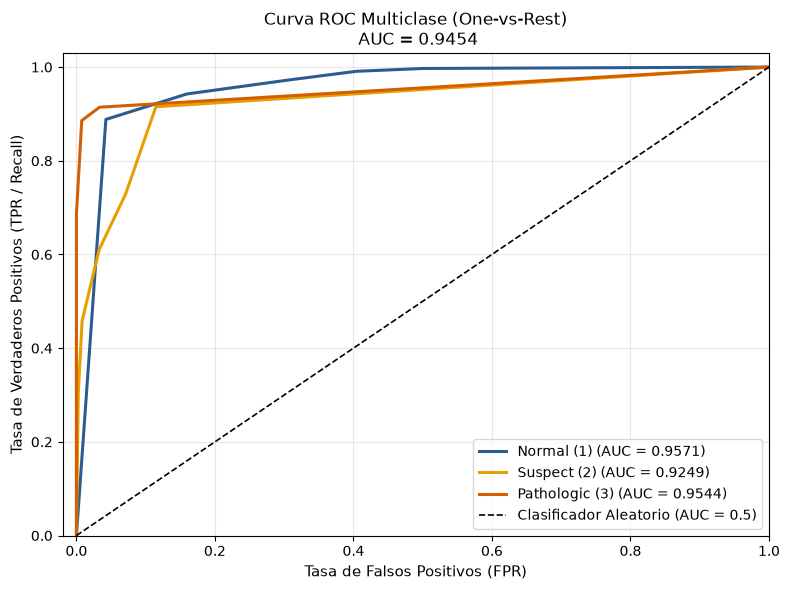

Macro AUC Global (Scikit-Learn): 0.9454


In [7]:
# Modelo Scikit-Learn
macro_auc_sk, aucs_por_clase_sk = roc(knn_sklearn, X_test, y_test)
print(f"Macro AUC Global (Scikit-Learn): {macro_auc_sk:.4f}")

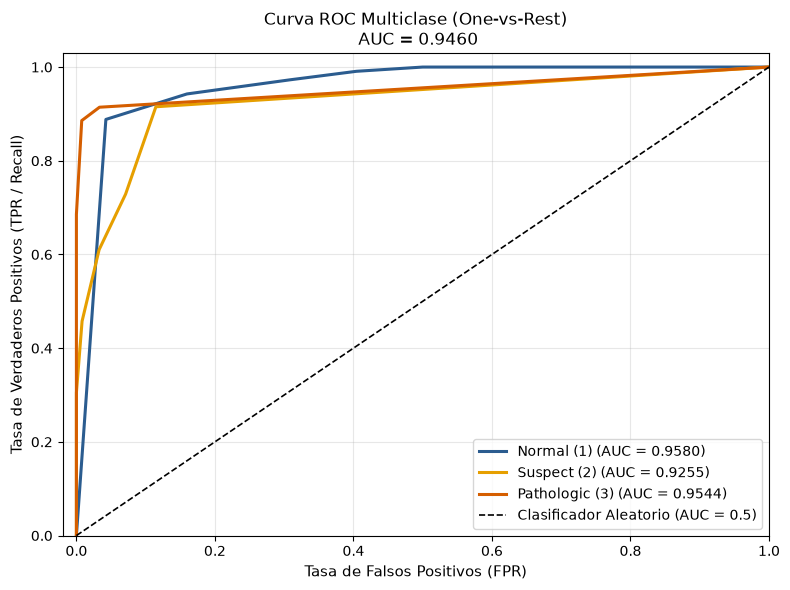

Macro AUC Global (Modelo Propio): 0.9460


In [8]:
# Nuestro Modelo
macro_auc_knn, aucs_por_clase_knn = roc(knn_model, X_test, y_test)
print(f"Macro AUC Global (Modelo Propio): {macro_auc_knn:.4f}")

#### Conclusión de la Comparativa (Modelo Propio vs. Scikit-Learn)




Al comparar nuestro KNN programado desde cero contra KNeighborsClassifier de scikit-learn bajo los mismos hiperparámetros (n_neighbors=5, métrica euclidiana), confirmamos que nuestra implementación reproduce correctamente el funcionamiento matemático del algoritmo:

- **Equivalencia en Calidad y Detección:** Ambas implementaciones obtuvieron resultados prácticamente idénticos, con una Exactitud Global de **90.12%** para nuestro modelo frente al **89.88%** de scikit-learn, y un Macro F1-Score de **81.64%** frente a **80.77%**. En la Clase 3 (Patológico), nuestro modelo alcanzó un Recall del **71.43%**, identificando 25 de los 35 casos críticos, mientras que scikit-learn obtuvo un **68.57%**, identificando 24. El Macro AUC también fue prácticamente idéntico (**0.9460** frente a **0.9454**), demostrando que ambas implementaciones tienen una capacidad de clasificación y discriminación muy similar.

- **Eficiencia Computacional y Costo de Búsqueda:** En la fase de entrenamiento, ambos modelos operan prácticamente de manera instantánea (**0.0006 s** frente a **0.0017 s**) debido a que KNN únicamente almacena los datos de entrenamiento. Sin embargo, durante la predicción existe una diferencia considerable: nuestra implementación en Python puro tarda **6.8244 s** en evaluar el conjunto de prueba, mientras que scikit-learn lo realiza en **2.1614 s** gracias a sus operaciones optimizadas.

En conclusión, nuestra implementación demuestra una calidad predictiva muy similar a la de una biblioteca profesional, pero presenta una desventaja en eficiencia durante la búsqueda de vecinos. KNN ofrece una clasificación consistente entre ambas implementaciones. Sin embargo, su capacidad para detectar casos patológicos sigue siendo inferior a la obtenida por los modelos de ensamble, por lo que sería conveniente explorar más ajustes en sus hiperparámetros y estrategias para mejorar la identificación de casos críticos.